In [21]:
# pandas = tables, matplotlib/seaborn = plots
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset (the notebook is in notebooks/, the CSV in data/)
df = pd.read_csv("../data/phishing_data.csv")

# First 5 rows: each row is one URL, each column is one feature
df.head()

,url,length_url,length_hostname,ip,nb_dots,nb_hyphens,nb_at,nb_qm,nb_and,nb_or,...,domain_in_title,domain_with_copyright,whois_registered_domain,domain_registration_length,domain_age,web_traffic,dns_record,google_index,page_rank,status
0,http://www.progarchives.com/album.asp?id=61737,46,20,zero,3,zero,0,1,0,0,...,1,one,0,627,6678,78526,0,0,5,phishing
1,http://signin.eday.co.uk.ws.edayisapi.dllsign....,128,120,0,10,0,0,0,0,0,...,1,zero,0,300,65,0,0,1,0,phishing
2,http://www.avevaconstruction.com/blesstool/ima...,52,25,0,3,0,0,0,0,0,...,1,zero,0,119,1707,0,0,1,0,phishing
3,http://www.jp519.com/,21,13,0,2,0,0,0,0,0,...,1,one,0,130,1331,0,0,0,0,legitimate
4,https://www.velocidrone.com/,28,19,0,2,0,0,0,0,0,...,0,zero,0,164,1662,312044,0,0,4,legitimate


In [22]:
# (number of rows, number of columns)
print(df.shape)

# Column names
print(df.columns.tolist())

(11481, 89)
['url', 'length_url', 'length_hostname', 'ip', 'nb_dots', 'nb_hyphens', 'nb_at', 'nb_qm', 'nb_and', 'nb_or', 'nb_eq', 'nb_underscore', 'nb_tilde', 'nb_percent', 'nb_slash', 'nb_star', 'nb_colon', 'nb_comma', 'nb_semicolumn', 'nb_dollar', 'nb_space', 'nb_www', 'nb_com', 'nb_dslash', 'http_in_path', 'https_token', 'ratio_digits_url', 'ratio_digits_host', 'punycode', 'port', 'tld_in_path', 'tld_in_subdomain', 'abnormal_subdomain', 'nb_subdomains', 'prefix_suffix', 'random_domain', 'shortening_service', 'path_extension', 'nb_redirection', 'nb_external_redirection', 'length_words_raw', 'char_repeat', 'shortest_words_raw', 'shortest_word_host', 'shortest_word_path', 'longest_words_raw', 'longest_word_host', 'longest_word_path', 'avg_words_raw', 'avg_word_host', 'avg_word_path', 'phish_hints', 'domain_in_brand', 'brand_in_subdomain', 'brand_in_path', 'suspecious_tld', 'statistical_report', 'nb_hyperlinks', 'ratio_intHyperlinks', 'ratio_extHyperlinks', 'ratio_nullHyperlinks', 'nb_e

In [23]:
# Columns that are NOT numeric. 'url' and 'status' are expected to be text,
# but 'ip', 'nb_hyphens' and 'domain_with_copyright' should be numbers.
print(df.select_dtypes(exclude="number").columns.tolist())

# Look at the values of the suspicious columns:
# you'll see words like "zero", "one", "Zero", "One" mixed with digits
for col in ["ip", "nb_hyphens", "domain_with_copyright"]:
    print(col)
    print(df[col].value_counts().head(8))
    print()

['url', 'ip', 'nb_hyphens', 'domain_with_copyright', 'status']
ip
ip
0       9374
1       1615
zero     410
one       82
Name: count, dtype: int64

nb_hyphens
nb_hyphens
0       6685
1       2145
2        893
3        426
zero     295
4        295
5        179
6        139
Name: count, dtype: int64

domain_with_copyright
domain_with_copyright
zero    5323
one     4149
Zero    1088
One      921
Name: count, dtype: int64



In [24]:
# Dictionary to translate number words into real numbers
word_to_num = {"zero": 0, "one": 1, "two": 2, "three": 3, "four": 4, "five": 5}

def to_number(value):
    # Make it lowercase text without spaces: "Zero " -> "zero"
    text = str(value).strip().lower()
    # If it's a number word, translate it; otherwise keep it ("2" stays "2")
    return word_to_num.get(text, text)

for col in ["ip", "nb_hyphens", "domain_with_copyright"]:
    # Apply the cleaning to every value, then convert to real numbers
    df[col] = pd.to_numeric(df[col].map(to_number))

# Check: the 3 columns should now be int64 with 0 missing values
print(df[["ip", "nb_hyphens", "domain_with_copyright"]].dtypes)
print(df[["ip", "nb_hyphens", "domain_with_copyright"]].isna().sum())

# Only 'url' and 'status' should remain as text
print(df.select_dtypes(exclude="number").columns.tolist())

ip                       int64
nb_hyphens               int64
domain_with_copyright    int64
dtype: object
ip                       0
nb_hyphens               0
domain_with_copyright    0
dtype: int64
['url', 'status']


In [25]:
# Inspect duplicates
print(df.duplicated().sum(), "duplicate rows")
print(df["url"].duplicated().sum(), "duplicate URLs")

# Do any duplicated URLs have conflicting labels?
conflicts = df.groupby("url")["status"].nunique()
print((conflicts > 1).sum(), "URLs with conflicting labels")

3480 duplicate rows
3481 duplicate URLs
0 URLs with conflicting labels


In [26]:
# Remove duplicates
df = df.drop_duplicates().reset_index(drop=True)
df = df.drop_duplicates(subset="url", keep="first").reset_index(drop=True)

print(df.shape)
print(df["status"].value_counts())

(8000, 89)
status
legitimate    4001
phishing      3999
Name: count, dtype: int64


In [27]:
# How many phishing vs legitimate URLs?
print(df["status"].value_counts())

# Missing values (models can't handle empty cells)
print(df.isna().sum().sum(), "missing values")

# Duplicate rows (could leak between train and test sets)
print(df.duplicated().sum(), "duplicate rows")

status
legitimate    4001
phishing      3999
Name: count, dtype: int64
0 missing values
0 duplicate rows


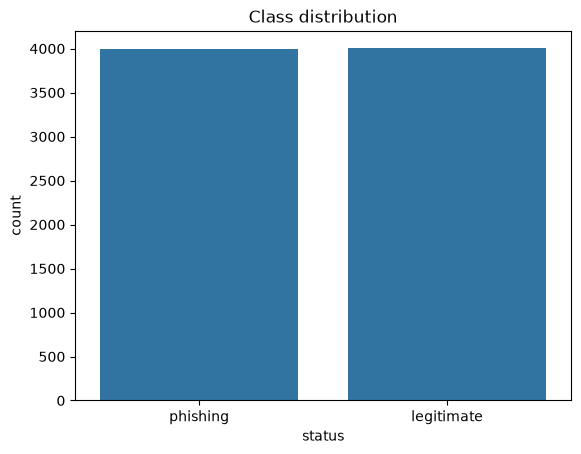

In [28]:
# One bar per class: the dataset should be close to 50/50
sns.countplot(x="status", data=df)
plt.title("Class distribution")
plt.show()

In [29]:
# Average of a few features for each class.
# Big differences = features that can help the model tell them apart.
cols = ["length_url", "nb_dots", "nb_hyphens", "nb_www"]
df.groupby("status")[cols].mean()

,length_url,nb_dots,nb_hyphens,nb_www
status,,,,
legitimate,47.431142,2.207698,1.217946,0.677331
phishing,74.866967,2.776944,0.777944,0.228557


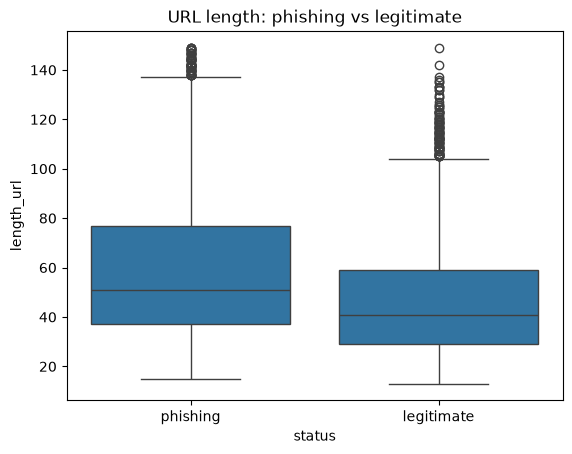

In [30]:
# Boxplot of URL length per class (limited to 150 characters to avoid extreme outliers)
sns.boxplot(x="status", y="length_url", data=df[df["length_url"] < 150])
plt.title("URL length: phishing vs legitimate")
plt.show()